# 05 升级版：用户-商品购买预测（用户明天会买哪件商品？）

**和 04 的区别：** 04 预测"用户明天会不会买任何东西"，信号太弱（ROC 曲线下面积约 0.62）。
这里把预测对象细化到**用户-商品对**：对每个用户最近 3 天互动过（浏览、收藏、加购、购买）的每件商品，预测他第二天会不会买**这件商品**。这是电商推荐和精准营销的真实场景，也是天池这个数据集的经典任务。

**建模设计：**

| | 特征窗口（7 天） | 候选商品 | 标签 |
|---|---|---|---|
| 训练集 | 11 月 25 日至 12 月 1 日 | 11 月 29 日至 12 月 1 日互动过的商品 | 12 月 2 日是否购买该商品 |
| 测试集 | 11 月 26 日至 12 月 2 日 | 11 月 30 日至 12 月 2 日互动过的商品 | 12 月 3 日是否购买该商品 |

**四类特征：**
- **用户-商品**：用户对这件商品浏览、收藏、加购、购买过几次，最近一次互动是多久前，是否"加购了但还没买"
- **用户**：用户整体的活跃度和购买习惯
- **商品与类目**：商品和类目有多受欢迎、转化率多高
- **用户-类目**：用户对这个类目有多感兴趣

**关键处理：**
- **按时间切分**，特征只用标签日之前的数据，避免数据泄漏
- **负样本下采样**：正样本（第二天真的买了）只占不到 1%，训练时保留全部正样本，按比例抽取负样本，加快训练、缓解类别不平衡；**测试集保留全部候选，不做抽样**，评估结果才真实

In [1]:
# 在 Google Colab 上运行时先执行这一格；在自己电脑上运行会自动跳过
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/ecommerce-user-behavior/notebooks")
    subprocess.run("pip -q install duckdb xgboost", shell=True, check=True)
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True, check=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts():
        if "NotoSansCJK" in f:
            fm.fontManager.addfont(f)
    print("Colab 环境准备完成，当前目录：", os.getcwd())

Mounted at /content/drive
Colab 环境准备完成，当前目录： /content/drive/MyDrive/ecommerce-user-behavior/notebooks


In [2]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, precision_score, recall_score)
from xgboost import XGBClassifier
import config, utils

utils.setup_plot()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = utils.connect()
BLUE, ORANGE, GREEN, GREY = "#3B6FB6", "#E07B39", "#4C9A6A", "#9AA5B1"

CAND_DAYS = 3      # 候选商品：标签日前几天内互动过的商品
NEG_RATIO = 10     # 训练集负样本数量 = 正样本数量 × NEG_RATIO

## 1. 用 SQL 构造用户-商品特征

In [3]:
def build_pairs(feat_start, label_date):
    sql = f'''
        WITH w AS (
            SELECT * FROM ub
            WHERE event_date >= DATE '{feat_start}' AND event_date < DATE '{label_date}'
        ),
        -- 用户-商品层面
        ui AS (
            SELECT
                user_id, item_id,
                ANY_VALUE(category_id)                                   AS category_id,
                COUNT(*) FILTER (WHERE behavior_type = 'pv')             AS ui_pv_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'fav')            AS ui_fav_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'cart')           AS ui_cart_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'buy')            AS ui_buy_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'pv'
                    AND event_date >= DATE '{label_date}' - INTERVAL 1 DAY) AS ui_pv_1d,
                COUNT(*) FILTER (WHERE behavior_type = 'cart'
                    AND event_date >= DATE '{label_date}' - INTERVAL 1 DAY) AS ui_cart_1d,
                COUNT(*) FILTER (WHERE behavior_type = 'fav'
                    AND event_date >= DATE '{label_date}' - INTERVAL 1 DAY) AS ui_fav_1d,
                COUNT(*) FILTER (WHERE behavior_type = 'pv'
                    AND event_date >= DATE '{label_date}' - INTERVAL 3 DAY) AS ui_pv_3d,
                COUNT(DISTINCT event_date)                               AS ui_active_days,
                date_diff('hour', MAX(event_time), TIMESTAMP '{label_date}') AS ui_hours_since_last,
                date_diff('hour', MAX(event_time) FILTER (WHERE behavior_type = 'cart'),
                          TIMESTAMP '{label_date}')                      AS ui_hours_since_cart,
                date_diff('hour', MAX(event_time) FILTER (WHERE behavior_type = 'fav'),
                          TIMESTAMP '{label_date}')                      AS ui_hours_since_fav,
                date_diff('hour', MAX(event_time) FILTER (WHERE behavior_type = 'buy'),
                          TIMESTAMP '{label_date}')                      AS ui_hours_since_buy,
                MAX(event_time)                                          AS last_time
            FROM w
            GROUP BY user_id, item_id
        ),
        cand AS (
            SELECT * FROM ui
            WHERE last_time >= TIMESTAMP '{label_date}' - INTERVAL {CAND_DAYS} DAY
        ),
        -- 用户层面
        u AS (
            SELECT
                user_id,
                COUNT(*) FILTER (WHERE behavior_type = 'pv')   AS u_pv_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'cart') AS u_cart_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'buy')  AS u_buy_7d,
                COUNT(DISTINCT event_date)                     AS u_active_days,
                COUNT(DISTINCT item_id)                        AS u_n_items
            FROM w GROUP BY user_id
        ),
        -- 商品层面：有多少人浏览、加购、购买
        i AS (
            SELECT
                item_id,
                COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'pv')   AS i_pv_users,
                COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'cart') AS i_cart_users,
                COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy')  AS i_buy_users
            FROM w GROUP BY item_id
        ),
        -- 类目层面
        c AS (
            SELECT
                category_id,
                COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'pv')  AS c_pv_users,
                COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy') AS c_buy_users
            FROM w GROUP BY category_id
        ),
        -- 用户-类目层面：用户对这个类目的兴趣
        uc AS (
            SELECT
                user_id, category_id,
                COUNT(*) FILTER (WHERE behavior_type = 'pv')   AS uc_pv_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'cart') AS uc_cart_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'buy')  AS uc_buy_7d,
                COUNT(DISTINCT item_id)                        AS uc_n_items
            FROM w GROUP BY user_id, category_id
        ),
        labels AS (
            SELECT DISTINCT user_id, item_id, 1 AS label
            FROM ub
            WHERE event_date = DATE '{label_date}' AND behavior_type = 'buy'
        )
        SELECT
            cand.* EXCLUDE (last_time),
            u.* EXCLUDE (user_id),
            i.* EXCLUDE (item_id),
            c.* EXCLUDE (category_id),
            uc.* EXCLUDE (user_id, category_id),
            COALESCE(labels.label, 0) AS label
        FROM cand
        JOIN u  ON cand.user_id = u.user_id
        JOIN i  ON cand.item_id = i.item_id
        JOIN c  ON cand.category_id = c.category_id
        JOIN uc ON cand.user_id = uc.user_id AND cand.category_id = uc.category_id
        LEFT JOIN labels ON cand.user_id = labels.user_id AND cand.item_id = labels.item_id
    '''
    df = con.execute(sql).df()
    total_bought = con.execute(f'''
        SELECT COUNT(*) FROM (SELECT DISTINCT user_id, item_id FROM ub
                              WHERE event_date = DATE '{label_date}' AND behavior_type = 'buy')
    ''').fetchone()[0]

    never = 8 * 24
    hour_cols = ["ui_hours_since_cart", "ui_hours_since_fav", "ui_hours_since_buy"]
    df[hour_cols] = df[hour_cols].fillna(never)
    df["ui_cart_not_bought"] = ((df["ui_cart_7d"] > 0) &
                                (df["ui_hours_since_buy"] > df["ui_hours_since_cart"])).astype(int)
    df["i_conv"] = df["i_buy_users"] / (df["i_pv_users"] + 1)
    df["i_cart_rate"] = df["i_cart_users"] / (df["i_pv_users"] + 1)
    df["c_conv"] = df["c_buy_users"] / (df["c_pv_users"] + 1)
    df["u_cart_to_buy"] = df["u_buy_7d"] / (df["u_cart_7d"] + 1)
    df["ui_share_in_cat"] = df["ui_pv_7d"] / (df["uc_pv_7d"] + 1)
    return df, int(total_bought)


t0 = time.time()
train_all, train_total_bought = build_pairs("2017-11-25", "2017-12-02")
test, test_total_bought = build_pairs("2017-11-26", "2017-12-03")
print(f"耗时 {time.time() - t0:.0f} 秒")

id_cols = ["user_id", "item_id", "category_id", "label"]
feature_cols = [c for c in train_all.columns if c not in id_cols]
for name, df, total in [("训练集", train_all, train_total_bought), ("测试集", test, test_total_bought)]:
    pos = int(df["label"].sum())
    print(f"{name}：{len(df):,} 个候选用户-商品对，其中第二天被购买 {pos:,} 个（{pos / len(df):.3%}）；"
          f"当天全部被购买的用户-商品对 {total:,} 个，候选集覆盖 {pos / total:.1%}")
print(f"特征数：{len(feature_cols)}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

耗时 83 秒
训练集：2,541,403 个候选用户-商品对，其中第二天被购买 5,462 个（0.215%）；当天全部被购买的用户-商品对 25,334 个，候选集覆盖 21.6%
测试集：2,815,180 个候选用户-商品对，其中第二天被购买 6,344 个（0.225%）；当天全部被购买的用户-商品对 24,867 个，候选集覆盖 25.5%
特征数：33


> **候选集覆盖率**是这类任务必须说明的口径：模型只能预测用户最近互动过的商品，第二天"临时起意"买的新商品不在预测范围内。面试时主动讲出来，说明你理解模型能做什么、不能做什么。

## 2. 负样本下采样，训练模型

In [4]:
pos = train_all[train_all["label"] == 1]
neg = train_all[train_all["label"] == 0]
neg = neg.sample(min(len(neg), len(pos) * NEG_RATIO), random_state=config.RANDOM_STATE)
train = pd.concat([pos, neg]).sample(frac=1, random_state=config.RANDOM_STATE)
print(f"下采样后训练集：{len(train):,} 行，正样本占 {train['label'].mean():.1%}"
      f"（下采样前 {train_all['label'].mean():.3%}）")

X_train, y_train = train[feature_cols].astype(float), train["label"]
X_test, y_test = test[feature_cols].astype(float), test["label"]
base_rate = y_test.mean()

models = {}
models["逻辑回归"] = make_pipeline(
    FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
    StandardScaler(),
    LogisticRegression(max_iter=3000),
).fit(X_train, y_train)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, stratify=y_train, random_state=config.RANDOM_STATE)
models["XGBoost"] = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=5, eval_metric="aucpr", early_stopping_rounds=100,
    tree_method="hist", n_jobs=-1, random_state=config.RANDOM_STATE,
).fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f"XGBoost 早停于第 {models['XGBoost'].best_iteration} 轮")

下采样后训练集：60,082 行，正样本占 9.1%（下采样前 0.215%）
XGBoost 早停于第 258 轮


## 3. 在全部测试候选上评估

正样本极少时，ROC 曲线下面积容易显得很高，所以重点看**平均精确率**和**前 K 名命中率**：
- **前 1% / 前 5% 命中率**：按得分取最靠前的候选，其中真正被购买的比例
- **覆盖率**：这些候选覆盖了多少实际购买
- **提升度**：命中率 ÷ 整体购买率，即比随机推荐好多少倍
- **前 N 名命中率**（N = 实际购买数）：如果推荐的数量正好等于实际购买数，能猜中多少

In [5]:
def top_metrics(y_true, score, frac=None, k=None):
    k = k or max(1, int(len(score) * frac))
    top = np.argsort(-score)[:k]
    hit = y_true.values[top].mean()
    return hit, y_true.values[top].sum() / y_true.sum(), hit / y_true.mean()


rules = {
    "规则：最近一天加购了该商品": (X_test["ui_cart_1d"] > 0).astype(int),
    "规则：加购了但还没买": X_test["ui_cart_not_bought"].astype(int),
}
rows, scores = [], {}
for name, pred in rules.items():
    rows.append({"方法": name, "精确率": precision_score(y_test, pred), "召回率": recall_score(y_test, pred)})
n_pos = int(y_test.sum())
for name, m in models.items():
    s = m.predict_proba(X_test)[:, 1]
    scores[name] = s
    h1, c1, l1 = top_metrics(y_test, s, frac=0.01)
    h5, c5, l5 = top_metrics(y_test, s, frac=0.05)
    hn, _, _ = top_metrics(y_test, s, k=n_pos)
    rows.append({"方法": name, "ROC曲线下面积": roc_auc_score(y_test, s),
                 "平均精确率": average_precision_score(y_test, s),
                 "前1%命中率": h1, "前1%覆盖率": c1, "前1%提升度": l1,
                 "前5%命中率": h5, "前5%覆盖率": c5, "前5%提升度": l5,
                 "前N名命中率": hn})
result = pd.DataFrame(rows).set_index("方法")
print(f"测试集候选 {len(y_test):,} 个，实际购买 {n_pos:,} 个，整体购买率 {base_rate:.3%}")
result.T

测试集候选 2,815,180 个，实际购买 6,344 个，整体购买率 0.225%


方法,规则：最近一天加购了该商品,规则：加购了但还没买,逻辑回归,XGBoost
精确率,0.0287,0.0160,NaN,NaN
召回率,0.3575,0.5654,NaN,NaN
ROC曲线下面积,NaN,NaN,0.8997,0.9043
平均精确率,NaN,NaN,0.0348,0.0382
前1%命中率,NaN,NaN,0.0525,0.0555
前1%覆盖率,NaN,NaN,0.2331,0.2462
前1%提升度,NaN,NaN,23.3140,24.6224
前5%命中率,NaN,NaN,0.0251,0.0254
前5%覆盖率,NaN,NaN,0.5560,0.5627
前5%提升度,NaN,NaN,11.1192,11.2547


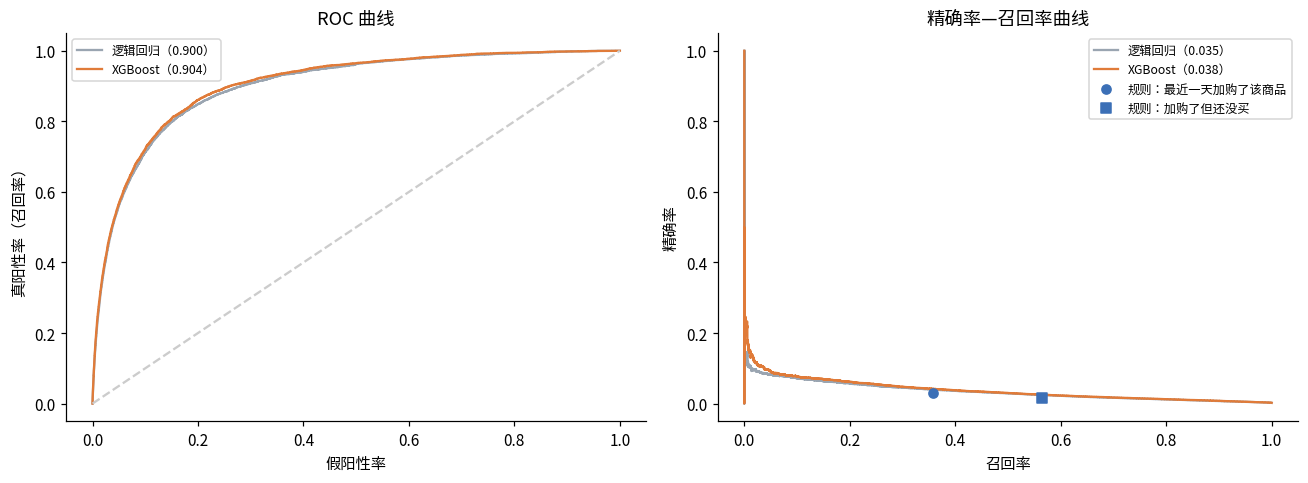

In [6]:
colors = {"逻辑回归": GREY, "XGBoost": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name}（{roc_auc_score(y_test, s):.3f}）")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=colors[name], label=f"{name}（{average_precision_score(y_test, s):.3f}）")
for (name, pred), mk in zip(rules.items(), ["o", "s"]):
    axes[1].scatter(recall_score(y_test, pred), precision_score(y_test, pred), marker=mk,
                    color=BLUE, zorder=5, label=name)
axes[0].plot([0, 1], [0, 1], "--", color="#cccccc")
axes[0].set(xlabel="假阳性率", ylabel="真阳性率（召回率）", title="ROC 曲线")
axes[1].set(xlabel="召回率", ylabel="精确率", title="精确率—召回率曲线")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
_ = utils.save_fig(fig, "05_模型评估曲线")

效果最好的模型：XGBoost


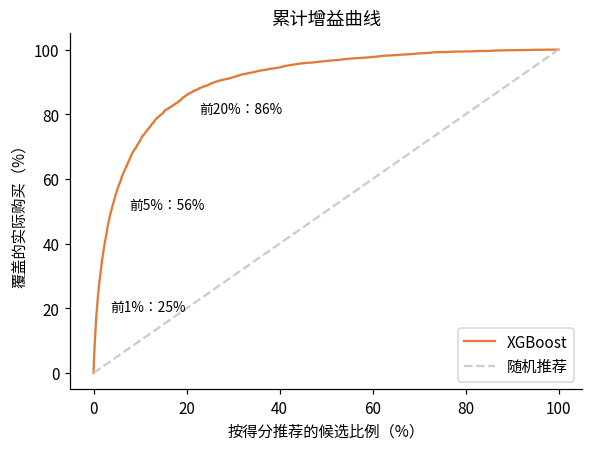

In [7]:
best = result["平均精确率"].idxmax()
s = scores[best]
order = np.argsort(-s)
cum_gain = np.cumsum(y_test.values[order]) / y_test.sum()
x = np.arange(1, len(s) + 1) / len(s)

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(x * 100, cum_gain * 100, color=ORANGE, label=best)
ax.plot([0, 100], [0, 100], "--", color="#cccccc", label="随机推荐")
for frac in (0.01, 0.05, 0.2):
    i = int(len(s) * frac) - 1
    ax.annotate(f"前{frac:.0%}：{cum_gain[i]:.0%}", (frac * 100, cum_gain[i] * 100),
                textcoords="offset points", xytext=(8, -12), fontsize=9)
ax.set(xlabel="按得分推荐的候选比例（%）", ylabel="覆盖的实际购买（%）", title="累计增益曲线")
ax.legend()
_ = utils.save_fig(fig, "05_累计增益曲线")
print(f"效果最好的模型：{best}")

## 4. 哪些信号最能预测买哪件商品？

XGBoost 最重要的 5 个特征： ['ui_cart_7d', 'ui_hours_since_cart', 'ui_cart_not_bought', 'ui_buy_7d', 'ui_hours_since_fav']
逻辑回归正向作用最强的 3 个特征： ['c_buy_users', 'ui_cart_not_bought', 'ui_buy_7d']
逻辑回归负向作用最强的 3 个特征： ['c_pv_users', 'u_n_items', 'ui_hours_since_last']


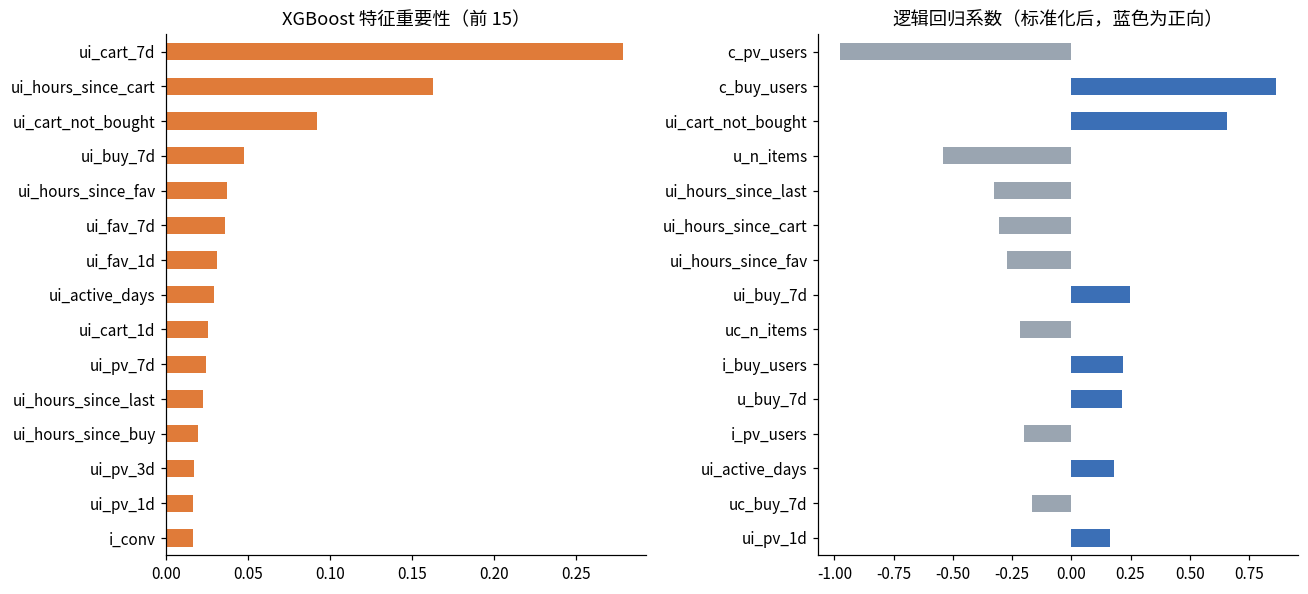

In [8]:
imp = pd.Series(models["XGBoost"].feature_importances_, index=feature_cols).sort_values()
coef = pd.Series(models["逻辑回归"][-1].coef_[0], index=feature_cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
imp.tail(15).plot.barh(ax=axes[0], color=ORANGE)
axes[0].set_title("XGBoost 特征重要性（前 15）")
top_coef = coef.reindex(coef.abs().sort_values().tail(15).index)
top_coef.plot.barh(ax=axes[1], color=[BLUE if v > 0 else GREY for v in top_coef])
axes[1].set_title("逻辑回归系数（标准化后，蓝色为正向）")
fig.tight_layout()
_ = utils.save_fig(fig, "05_特征重要性")
print("XGBoost 最重要的 5 个特征：", list(imp.tail(5).index[::-1]))
print("逻辑回归正向作用最强的 3 个特征：", list(coef.tail(3).index[::-1]))
print("逻辑回归负向作用最强的 3 个特征：", list(coef.head(3).index))

In [9]:
result.to_csv(config.RESULTS_DIR / "05_模型对比.csv", encoding="utf-8-sig")
r = result.loc[best]
utils.update_summary("05_用户商品购买预测", {
    "候选天数": CAND_DAYS,
    "负样本比例": NEG_RATIO,
    "训练候选数": int(len(train_all)),
    "下采样后训练行数": int(len(train)),
    "测试候选数": int(len(test)),
    "测试实际购买数": n_pos,
    "测试候选集覆盖率": round(n_pos / test_total_bought, 4),
    "测试整体购买率": round(float(base_rate), 5),
    "最佳模型": best,
    "各模型ROC曲线下面积": {k: round(float(v), 4) for k, v in result["ROC曲线下面积"].dropna().items()},
    "各模型平均精确率": {k: round(float(v), 4) for k, v in result["平均精确率"].dropna().items()},
    "最佳_前1%命中率": round(float(r["前1%命中率"]), 4),
    "最佳_前1%覆盖率": round(float(r["前1%覆盖率"]), 4),
    "最佳_前1%提升度": round(float(r["前1%提升度"]), 1),
    "最佳_前5%命中率": round(float(r["前5%命中率"]), 4),
    "最佳_前5%覆盖率": round(float(r["前5%覆盖率"]), 4),
    "最佳_前5%提升度": round(float(r["前5%提升度"]), 1),
    "最佳_前N名命中率": round(float(r["前N名命中率"]), 4),
    "规则_最近一天加购_精确率": round(float(result.iloc[0]["精确率"]), 4),
    "规则_最近一天加购_召回率": round(float(result.iloc[0]["召回率"]), 4),
    "规则_加购未买_精确率": round(float(result.iloc[1]["精确率"]), 4),
    "规则_加购未买_召回率": round(float(result.iloc[1]["召回率"]), 4),
    "XGBoost前5特征": list(imp.tail(5).index[::-1]),
})
print("已写入 results/summary.json")

已写入 results/summary.json


## 小结（跑完后填写）

- 和 04 相比，把预测对象细化到用户-商品后，效果提升了多少？
- 最强的购买信号是什么？
- 业务应用：每天给每位用户推荐得分最高的几件商品，或对高分的"加购未买"商品发放优惠券
- 局限：只能预测最近互动过的商品（候选集覆盖率）；只有 9 天数据，没有价格和用户画像